Notebook ini menelusuri satu pertanyaan: apakah struktur prompt tiga modul SocioMathLLM dapat dipakai untuk tugas debugging C? Setiap langkah menunjukkan input, keputusan, dan buktinya. Angka dibaca dari artifact hasil run yang sebenarnya, bukan dihitung ulang dari data mentah.

## 1. Data dan pertanyaan

Kami mulai dari konfigurasi karena seed, arsip, dan model menetapkan batas reproduksi. Pertanyaannya: apakah pipeline menghasilkan tugas yang lolos pemeriksaan eksekusi dan memenuhi rubrik sosial?

```python
def load_config(path: Path) -> dict:
    with path.open(encoding="utf-8") as fh:
        return yaml.safe_load(fh)
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
D = ROOT / "experiments" / "EXP-001"
FIG = ROOT / "experiments" / "outputs" / "EXP-001" / "figures"
PROCESSED = ROOT / "data" / "processed" / "EXP-001"

cfg = yaml.safe_load((D / "config.yaml").read_text(encoding="utf-8"))
manifest = json.loads((D / "data-manifest.json").read_text(encoding="utf-8"))
metrics = json.loads((D / "metrics.json").read_text(encoding="utf-8"))


def show_figure(name: str) -> None:
    plt.figure(figsize=(10, 4))
    plt.imshow(plt.imread(FIG / name))
    plt.axis("off")
    plt.show()


summary = pd.DataFrame(
    [
        ("seed", cfg["seed"]),
        ("dataset", cfg["data"]["name"]),
        ("n_available", manifest["n_items_available"]),
        ("n_selected", cfg["data"]["n_items"]),
        ("model", cfg["model"]["name"]),
        ("temperature", cfg["model"]["temperature"]),
        ("run_id", metrics["run_id"]),
    ],
    columns=["field", "value"],
)
print(summary.to_string(index=False))

      field                                   value
       seed                                20261123
    dataset                                    ITSP
n_available                                     661
 n_selected                                      20
      model                     deepseek-v4.1-flash
temperature                                     0.7
     run_id EXP-001-20261124T035513458240Z-f8283ecc


## 2. Dari arsip ke contoh butir

Dari 661 butir ITSP, seed yang sama memilih 20 butir secara deterministik. Ini pilot yang bisa ditelusur sampai id butir, bukan dasar generalisasi statistik.

```python
def load_items(cfg: dict) -> list[dict]:
    data = dataset_root(cfg)
    items: list[dict] = []
    for main in sorted(data.glob("Lab-*/*/Main.c")):
        lab, prob_id = main.parent.parent.name, main.parent.name
        tests = []
        for inp in sorted(
            (data / "test").glob(f"in.{prob_id}.*.txt"),
            key=lambda p: int(p.name.split(".")[-2]),
        ):
            idx = inp.name.split(".")[-2]
            out = data / "test" / f"out.{prob_id}.{idx}.txt"
            if out.is_file():
                tests.append((inp.read_text(encoding="utf-8", errors="replace"),
                              out.read_text(encoding="utf-8", errors="replace")))
        for buggy in sorted(main.parent.glob("*_buggy.c")):
            student = buggy.name.removesuffix("_buggy.c")
            correct = main.parent / f"{student}_correct.c"
            if not correct.is_file() or not tests:
                continue
            items.append({
                "item_id": f"{lab}-{prob_id}-{student}",
                "lab": lab,
                "difficulty_proxy": int(lab.split("-")[-1]),
                "statement": statement_from_main(main),
                "buggy_code": buggy.read_text(encoding="utf-8", errors="replace"),
                "correct_code": correct.read_text(encoding="utf-8", errors="replace"),
                "tests": tests,
            })
    return items
```

In [2]:
items = pd.DataFrame(
    [json.loads(line) for line in (PROCESSED / "items.jsonl").read_text(encoding="utf-8").splitlines() if line.strip()]
)
sample = items[["item_id", "lab", "difficulty_proxy"]].head(2).copy()
sample["statement_preview"] = items["statement"].head(2).str.replace("\n", " ", regex=False).str[:60] + "..."
sample["n_tests"] = items["tests"].head(2).apply(len)
print(sample.to_string(index=False))

generations = pd.DataFrame(
    [json.loads(line) for line in (PROCESSED / "generations.jsonl").read_text(encoding="utf-8").splitlines() if line.strip()]
)
print("\nContoh final_task:")
print(generations["final_task"].iloc[0][:420])

           item_id    lab  difficulty_proxy                                               statement_preview  n_tests
Lab-10-3241-303532 Lab-10                10 Up to 20% marks will be allotted for good programming practi...        5
Lab-11-3291-305271 Lab-11                11 -------------------------------------------- Up to 20% marks...        6

Contoh final_task:
COLLABORATION: Together, locate the fault in the divisibility verification loop.

COOPERATION: Split into driver and navigator roles — one runs the tests and reports output, the other reads the code structure.

NEGOTIATION: Disagree about the root cause of the indexing failure and agree on which patch to apply.

IDEAS_SHARING: Explain and justify your hypothesis about where the nested-loop indexing goes wrong, using 


## 3. Kompilasi dan fail-to-pass

Sebelum menilai teks, kami memeriksa apakah kode buggy dan kode benar benar-benar berbeda perilaku. Hanya butir yang lolos fail-to-pass yang layak dijadikan bukti.

```python
def execution_metrics(items: list[dict], cfg: dict, trace: RunLog) -> tuple[list[dict], dict]:
    results = []
    with tempfile.TemporaryDirectory() as td:
        work = Path(td)
        for item in items:
            item_id = item["item_id"]
            with trace.item(item_id):
                buggy = compile_and_run(
                    item["buggy_code"], item["tests"], work, cfg, trace, "buggy", item_id
                )
                correct = compile_and_run(
                    item["correct_code"], item["tests"], work, cfg, trace, "correct", item_id
                )
                for variant, result in (("buggy", buggy), ("correct", correct)):
                    trace.event(
                        "item_executed", variant=variant, compiled=result["compiled"],
                        passed=result["passed"], total=result["total"],
                    )
                trace.event(
                    "item_compiled",
                    buggy_compiled=buggy["compiled"], correct_compiled=correct["compiled"],
                    buggy_passed=buggy["passed"], correct_passed=correct["passed"],
                    total=buggy["total"],
                )
            results.append({"item_id": item_id, "buggy": buggy, "correct": correct})
    n = len(results)
    fail_to_pass = sum(
        1 for r in results
        if r["buggy"]["compiled"] and r["correct"]["compiled"]
        and r["buggy"]["passed"] < r["correct"]["passed"]
    )
    return results, {
        "n_items": n,
        "buggy_compiled": sum(r["buggy"]["compiled"] for r in results),
        "correct_compiled": sum(r["correct"]["compiled"] for r in results),
        "fail_to_pass_items": fail_to_pass,
        "fail_to_pass_rate": round(fail_to_pass / n, 4) if n else 0.0,
    }
```

            metric  value
           n_items   20.0
    buggy_compiled   17.0
  correct_compiled   16.0
fail_to_pass_items   14.0
 fail_to_pass_rate    0.7


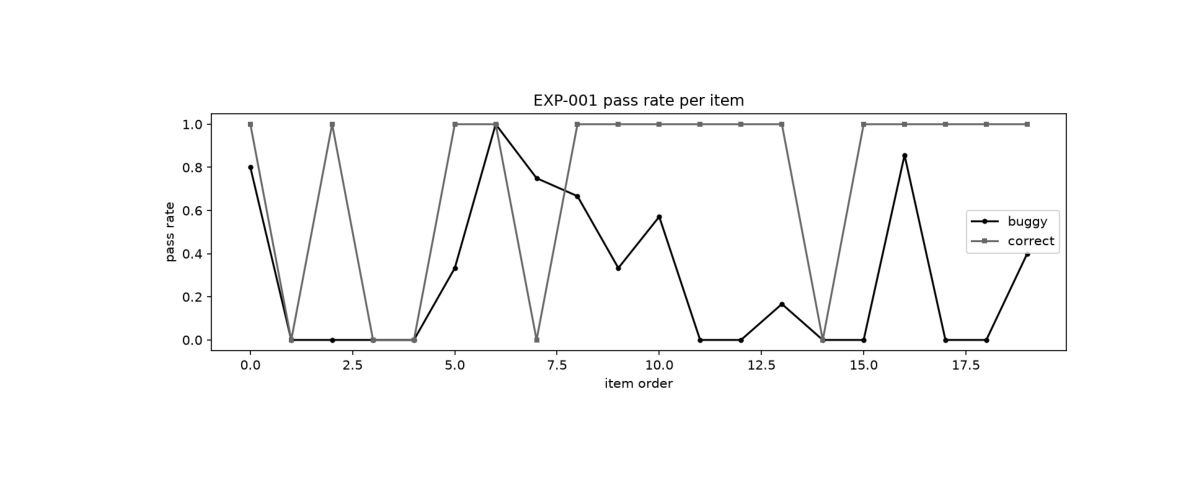

In [3]:
execution = pd.DataFrame(list(metrics["execution"].items()), columns=["metric", "value"])
print(execution.to_string(index=False))
show_figure("pass_rate_per_item.png")

## 4. Prompt dan judge

Setelah kode tervalidasi, tiga modul prompt menghasilkan tugas dan satu judge menilai empat cue sosial. Skor ini mengukur teks tugas, bukan perilaku mahasiswa.

```python
def call_llm_traced(
    cfg: dict, messages: list[dict], session: str,
    trace: RunLog, module: str,
```

    dimension  mean_score
collaboration        4.15
  cooperation        4.00
  negotiation        3.55
ideas_sharing        4.20
judge_parseable: 20/20


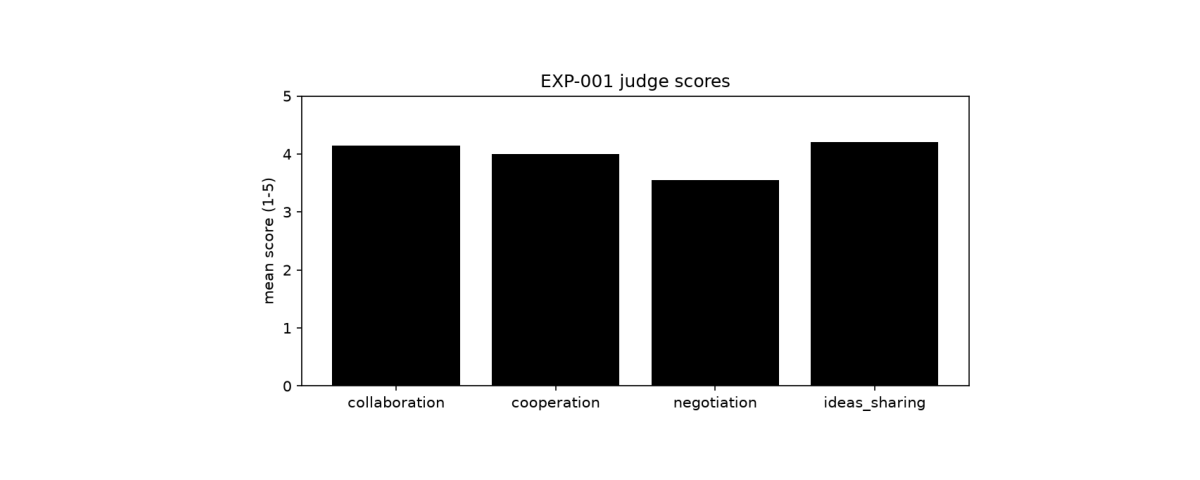

In [4]:
judge = pd.DataFrame(
    list(metrics["generation"]["mean_by_dimension"].items()),
    columns=["dimension", "mean_score"],
)
print(judge.to_string(index=False))
print(f"judge_parseable: {metrics['generation']['judge_parseable']}/{metrics['generation']['n_items']}")
show_figure("judge_scores.png")

## 5. Trace core

Setiap panggilan tercatat supaya angka bisa dikaitkan dengan satu run. RunLog menolak config yang berubah dan menghitung attempt saat judge gagal dibaca.

```python
    def _next_attempt(self) -> int:
        if not self.events_path.is_file():
            return 1
        attempts = []
        for line in self.events_path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            event = json.loads(line)
            previous = event.get("config_sha256")
            if previous is not None and previous != self.config_sha256:
                raise ConfigChangedError(
                    f"{self.events_path} holds config_sha256={previous}; "
                    f"current config_sha256={self.config_sha256}"
                )
            if isinstance(event.get("attempt"), int):
                attempts.append(event["attempt"])
        return max(attempts, default=0) + 1

    def _write(self, name: str, **payload: Any) -> None:
        event = {
            "event": name,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "t_s": round(monotonic() - self._mono_start, 3),
            "run_id": self.run_id,
            "attempt": self.attempt,
        }
        if self._stage:
            event["stage"] = self._stage
        if self._item_id:
            event["item_id"] = self._item_id
        event.update(payload)
        self._fh.write(json.dumps(event, ensure_ascii=False, default=str) + "\n")
        self._fh.flush()

    def start(self, *, mode: str, config_sha256: str | None = None, **payload: Any) -> None:
        self._write(
            "started",
            mode=mode,
            config_sha256=config_sha256 or self.config_sha256,
            git_sha=git_sha(self.repo),
            **payload,
        )
```

event
item_executed      120
item_prompted       80
judge_scored        80
item_compiled       60
compile_failed      21
item_parsed         20
stage_started       11
stage_completed     11
started              3
completed            3
failed               1


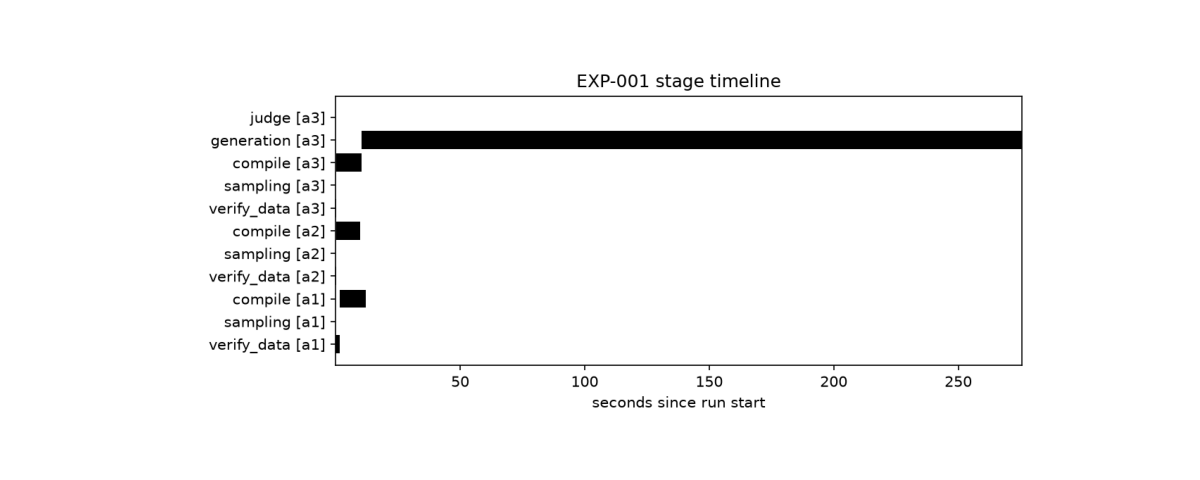

In [5]:
events = [
    json.loads(line)
    for line in (D / "events.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
event_counts = pd.Series([event["event"] for event in events]).value_counts()
print(event_counts.rename_axis("event").rename("count").to_string())
show_figure("stage_timeline.png")

## 6. Provenance dan artifact lokal

Provenance mengunci versi dan hash supaya run lain tidak tercampur. Ringkasan kegagalan menjelaskan bagian yang tidak ikut dihitung.

```python
    def write_provenance(self, **extra: Any) -> None:
        payload: dict[str, Any] = {
            "experiment": self.experiment_id,
            "run_id": self.run_id,
            "attempt": self.attempt,
            "config_sha256": self.config_sha256,
            "git_sha": git_sha(self.repo),
            "started_utc": self.started_utc,
            "python": platform.python_version(),
            "platform": platform.platform(),
            "wall_time_s": self._wall_time(),
        }
        if resource is not None:
            payload["peak_rss_mb"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 2)
        payload.update(extra)
        self.provenance_path.write_text(
            json.dumps(payload, indent=2, default=str) + "\n", encoding="utf-8"
        )
```

        field                                                            value
   experiment                                                          EXP-001
       run_id                          EXP-001-20261124T035513458240Z-f8283ecc
      attempt                                                                3
config_sha256 f8283ecc6edd0d528b403ce61030e7d53cb1a01cc39df1913aaec23e549cbde8
      git_sha                         29bad9fc2ea313b90d198e1b684ff5bdba6e380f
  started_utc                                 2026-11-24T03:55:13.458225+00:00
       python                                                          3.13.16
     platform     Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.43
  wall_time_s                                                          275.433
  peak_rss_mb                                                            34.35
  data_sha256 7d2329ca5cd1009ee0c7518095a13b18fb82a6931750ece27014a83f5d13dec0
          gcc                             gcc (Ubunt

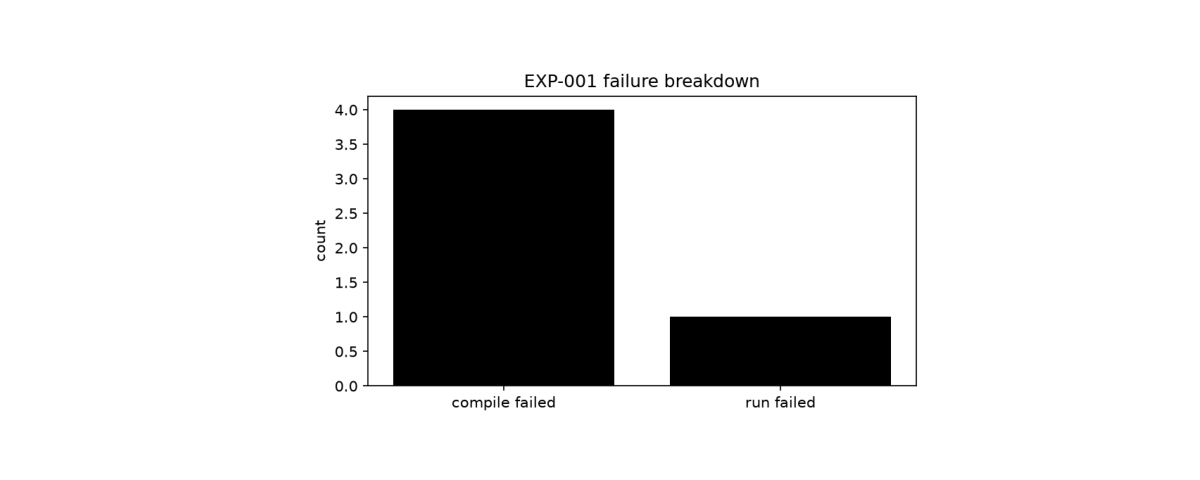

In [6]:
provenance = json.loads((D / "provenance.json").read_text(encoding="utf-8"))
rows = [(key, value) for key, value in provenance.items() if not isinstance(value, (dict, list))]
print(pd.DataFrame(rows, columns=["field", "value"]).to_string(index=False))
show_figure("failure_breakdown.png")

## 7. Dari kode ke plot

Plot dibangun ulang dari artifact yang sama, bukan dari angka yang ditulis manual. Notebook menampilkannya pada langkah yang memakainya.

```python
def main() -> None:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    plt.style.use("grayscale")
    summary = summarize(load_events(EXP_DIR / "events.jsonl"))
    metrics = json.loads((EXP_DIR / "metrics.json").read_text(encoding="utf-8"))
    plot_stage_timeline(summary)
    plot_pass_rates(metrics)
    plot_judge(metrics)
    plot_failures(summary, metrics)
    print(f"figures: {OUT_DIR}")
```

In [7]:
figures = sorted(path.name for path in FIG.glob("*.png"))
print("artifact plot:")
print("\n".join(f"- {name}" for name in figures))

artifact plot:
- failure_breakdown.png
- judge_scores.png
- pass_rate_per_item.png
- stage_timeline.png
